# NLP Assignment: Text Cleaning, Embeddings, and Sequential Models (RNN / LSTM / GRU)

**Dataset:** IMDB Movie Reviews (50,000 reviews, binary sentiment: positive / negative)

**Objectives**
1. **Text Cleaning** — preprocess raw review text for modeling.
2. **Embeddings** — convert cleaned text into numerical vectors that capture semantic meaning (Keras trainable embeddings + a custom Word2Vec).
3. **Sequential Models** — build, train and compare a SimpleRNN, an LSTM, and a GRU for sentiment classification.

*Note on scale:* the notebook runs on a single CPU core, so modeling is done on a stratified subsample (6,000 reviews) of the full 50k dataset (with the full set used for cleaning/EDA) to keep training times reasonable while still producing meaningful, reproducible comparisons. Models are trained for up to 16 epochs with early stopping on validation accuracy, and use spatial/recurrent dropout to reduce overfitting on the smaller subsample.


## 1. Setup & Imports

In [1]:
import re
import string
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout, Bidirectional, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)

from gensim.models import Word2Vec

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

print('TensorFlow version:', tf.__version__)


I0000 00:00:1786651642.085901    1896 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786651642.135330    1896 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1786651643.552621    1896 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


## 2. Load & Explore the Dataset

In [2]:
df = pd.read_csv('/mnt/user-data/uploads/IMDB_Dataset.csv')
print('Shape:', df.shape)
df.head(3)


Shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive


In [3]:
print(df['sentiment'].value_counts())
print('\nMissing values:\n', df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())


sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Missing values:
 review       0
sentiment    0
dtype: int64



Duplicate rows: 418


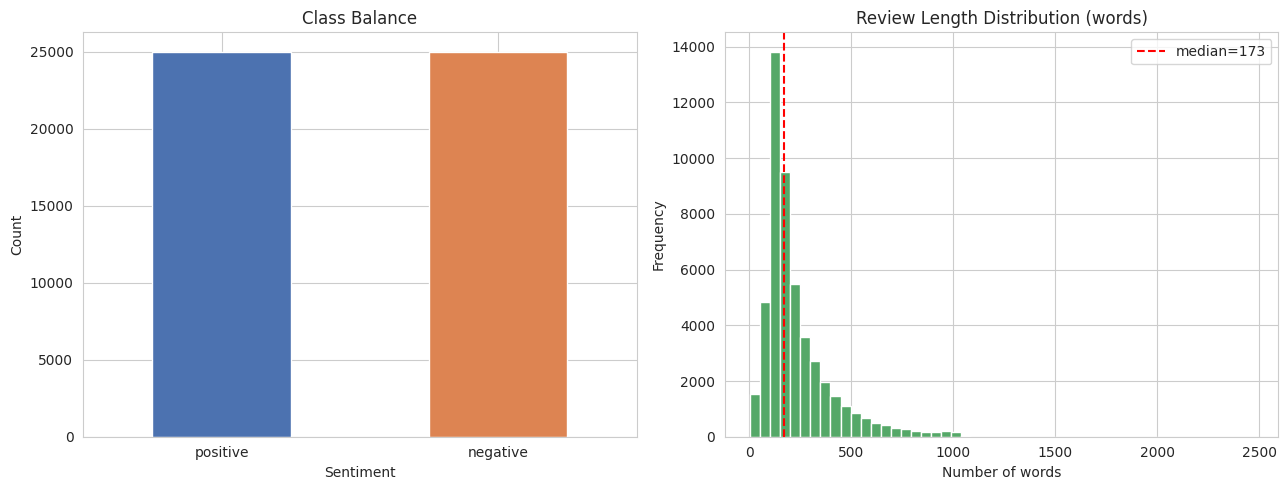

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: review, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df['sentiment'].value_counts().plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'])
axes[0].set_title('Class Balance')
axes[0].set_xlabel('Sentiment'); axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

review_lengths = df['review'].str.split().apply(len)
axes[1].hist(review_lengths, bins=50, color='#55A868')
axes[1].set_title('Review Length Distribution (words)')
axes[1].set_xlabel('Number of words'); axes[1].set_ylabel('Frequency')
axes[1].axvline(review_lengths.median(), color='red', linestyle='--', label=f'median={review_lengths.median():.0f}')
axes[1].legend()

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=110)
plt.show()

print(review_lengths.describe())


The dataset is **perfectly balanced** (25,000 positive / 25,000 negative), so accuracy is a fair evaluation metric. Reviews vary widely in length, with a long right tail — this motivates padding/truncating sequences to a fixed length for the neural models.

## 3. Text Cleaning

Raw IMDB reviews contain HTML tags (e.g. `<br />`), punctuation, numbers, mixed casing, and stopwords that add little semantic value for sentiment classification. The cleaning pipeline below:

1. Removes HTML tags
2. Removes URLs
3. Expands common contractions (e.g. "don't" → "do not")
4. Lowercases text
5. Removes punctuation and digits
6. Tokenizes into words
7. Removes stopwords (keeping negations like *not*, *no*, *never*, which matter for sentiment)
8. Lemmatizes tokens to their base form


In [5]:
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('omw-1.4', quiet=True)

stop_words = set(stopwords.words('english'))
# Keep negation words - they flip sentiment meaning and are important signal
negations = {'no', 'not', 'nor', 'never', "n't", 'none', 'nothing', 'neither'}
stop_words = stop_words - negations

lemmatizer = WordNetLemmatizer()

CONTRACTIONS = {
    "don't": "do not", "doesn't": "does not", "didn't": "did not",
    "won't": "will not", "wouldn't": "would not", "can't": "can not",
    "couldn't": "could not", "shouldn't": "should not", "isn't": "is not",
    "aren't": "are not", "wasn't": "was not", "weren't": "were not",
    "haven't": "have not", "hasn't": "has not", "hadn't": "had not",
    "it's": "it is", "that's": "that is", "there's": "there is",
    "i'm": "i am", "i've": "i have", "i'll": "i will", "i'd": "i would",
}

def expand_contractions(text):
    for c, exp in CONTRACTIONS.items():
        text = re.sub(re.escape(c), exp, text)
    return text

def clean_text(text, remove_stopwords=True, lemmatize=True):
    text = str(text)
    text = re.sub(r'<.*?>', ' ', text)                      # HTML tags (e.g. <br />)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)          # URLs
    text = text.lower()
    text = expand_contractions(text)
    text = re.sub(r"[^a-z\s]", ' ', text)                    # punctuation & digits
    text = re.sub(r'\s+', ' ', text).strip()

    tokens = text.split()
    if remove_stopwords:
        tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    if lemmatize:
        tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

# Demo on a single review
sample = df['review'].iloc[0]
print('--- RAW ---')
print(sample[:400])
print('\n--- CLEANED ---')
print(clean_text(sample)[:400])


--- RAW ---
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to

--- CLEANED ---


one reviewer mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use word called oz nickname given oswald maximum security state penitentary focus mainly emerald city experimental section prison cell glass front face in


In [6]:
t0 = time.time()
df['clean_review'] = df['review'].apply(clean_text)
print(f'Cleaned {len(df)} reviews in {time.time()-t0:.1f}s')

df['clean_token_count'] = df['clean_review'].str.split().apply(len)
df[['review', 'clean_review', 'clean_token_count']].head(3)


Cleaned 50000 reviews in 29.5s


,review,clean_review,clean_token_count
0,One of the other reviewers has mentioned that ...,one reviewer mentioned watching oz episode hoo...,171
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...,88
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...,87


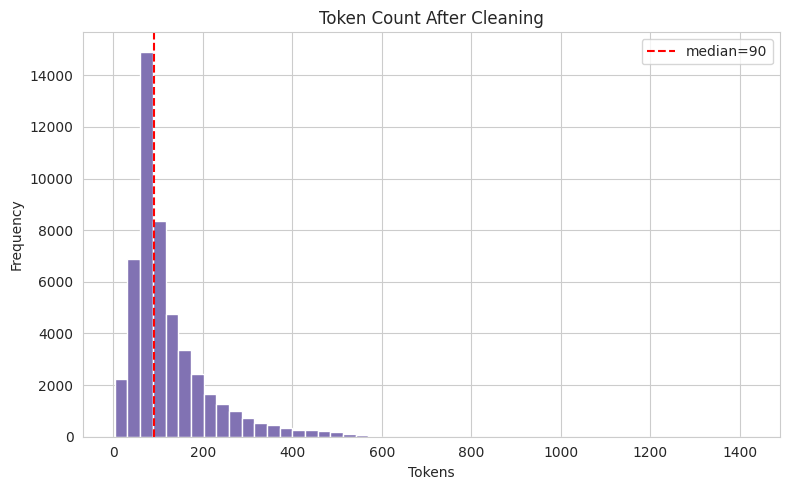

In [7]:
fig, ax = plt.subplots(figsize=(8,5))
ax.hist(df['clean_token_count'], bins=50, color='#8172B3')
ax.axvline(df['clean_token_count'].median(), color='red', linestyle='--',
           label=f"median={df['clean_token_count'].median():.0f}")
ax.set_title('Token Count After Cleaning')
ax.set_xlabel('Tokens'); ax.set_ylabel('Frequency'); ax.legend()
plt.tight_layout()
plt.savefig('clean_token_dist.png', dpi=110)
plt.show()


### Word Frequency — Most Common Words by Sentiment

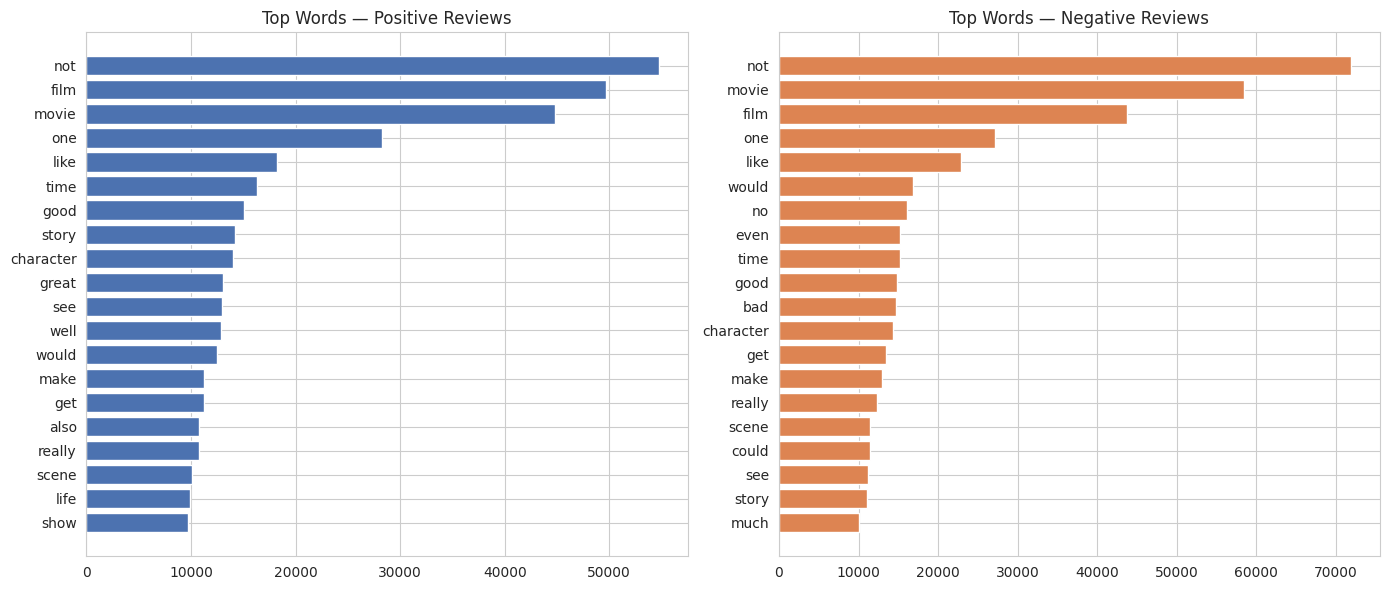

In [8]:
from collections import Counter

def top_words(series, n=20):
    words = ' '.join(series).split()
    return Counter(words).most_common(n)

pos_top = top_words(df.loc[df['sentiment']=='positive', 'clean_review'])
neg_top = top_words(df.loc[df['sentiment']=='negative', 'clean_review'])

fig, axes = plt.subplots(1, 2, figsize=(14,6))
axes[0].barh([w for w,_ in pos_top][::-1], [c for _,c in pos_top][::-1], color='#4C72B0')
axes[0].set_title('Top Words — Positive Reviews')
axes[1].barh([w for w,_ in neg_top][::-1], [c for _,c in neg_top][::-1], color='#DD8452')
axes[1].set_title('Top Words — Negative Reviews')
plt.tight_layout()
plt.savefig('top_words.png', dpi=110)
plt.show()


## 4. Embeddings

We convert cleaned text into numerical vectors two ways:

1. **Keras `Tokenizer` + trainable `Embedding` layer** — words are mapped to integer IDs, padded to a fixed length, and an embedding matrix is *learned jointly* with the sentiment classifier.
2. **Word2Vec (Skip-gram, via Gensim)** — trained on the cleaned corpus to learn dense vectors purely from word co-occurrence, independent of the classification task. We inspect nearest neighbours to confirm the embeddings capture semantic meaning, and use the resulting vectors to *initialize* the embedding layer of one of our sequential models.


In [9]:
# ---- Sub-sample for modeling (single-CPU environment) ----
N_SAMPLES = 6000   # stratified subsample of the 50k reviews
pos_sample = df[df['sentiment'] == 'positive'].sample(N_SAMPLES // 2, random_state=SEED)
neg_sample = df[df['sentiment'] == 'negative'].sample(N_SAMPLES // 2, random_state=SEED)
df_model = pd.concat([pos_sample, neg_sample]).sample(frac=1, random_state=SEED).reset_index(drop=True)

df_model['label'] = (df_model['sentiment'] == 'positive').astype(int)
print(df_model['sentiment'].value_counts())
df_model.head(2)


sentiment
positive    3000
negative    3000
Name: count, dtype: int64


,review,sentiment,clean_review,clean_token_count,label
0,Many American pea-brains who worship and suppo...,positive,many american pea brain worship support politi...,98,1
1,Probably somebody heard of Alberto Tomba. A fo...,negative,probably somebody heard alberto tomba former p...,101,0


In [10]:
VOCAB_SIZE = 10000
MAX_LEN = 150

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(df_model['clean_review'])

sequences = tokenizer.texts_to_sequences(df_model['clean_review'])
X = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')
y = df_model['label'].values

print('X shape:', X.shape)
print('Vocabulary size found:', len(tokenizer.word_index))
print('Example sequence (padded):', X[0][:20])


X shape: (6000, 150)
Vocabulary size found: 36608
Example sequence (padded): [  40  143 8029  709 5365 1130  743  187  647    1    6  350 1442    8
   19  763    3   16 8713    1]


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print('Train:', X_train.shape, ' Test:', X_test.shape)


Train: (4800, 150)  Test: (1200, 150)


### Word2Vec Embeddings (Gensim)

We train a Skip-gram Word2Vec model on the tokenized, cleaned reviews. This gives us dense vectors where semantically similar words end up close together in vector space.


In [12]:
tokenized_corpus = [text.split() for text in df_model['clean_review']]

w2v_model = Word2Vec(
    sentences=tokenized_corpus,
    vector_size=100,
    window=5,
    min_count=3,
    workers=1,
    sg=1,          # skip-gram
    epochs=10,
    seed=SEED
)
print('Vocabulary learned:', len(w2v_model.wv.key_to_index))


Vocabulary learned: 17109


In [13]:
# Sanity-check the semantic quality of the embeddings
for query in ['great', 'terrible', 'movie', 'boring']:
    if query in w2v_model.wv:
        neighbours = w2v_model.wv.most_similar(query, topn=6)
        print(f"{query:>10} -> {[w for w,_ in neighbours]}")


     great -> ['excellent', 'superb', 'rocked', 'fantastic', 'apt', 'forgiving']
  terrible -> ['abysmal', 'awful', 'atrocious', 'ranged', 'horrid', 'lamest']
     movie -> ['film', 'definately', 'pic', 'purist', 'priyadarshan', 'astonished']
    boring -> ['dull', 'excruciatingly', 'tiresome', 'incomprehensible', 'rambling', 'unimaginative']


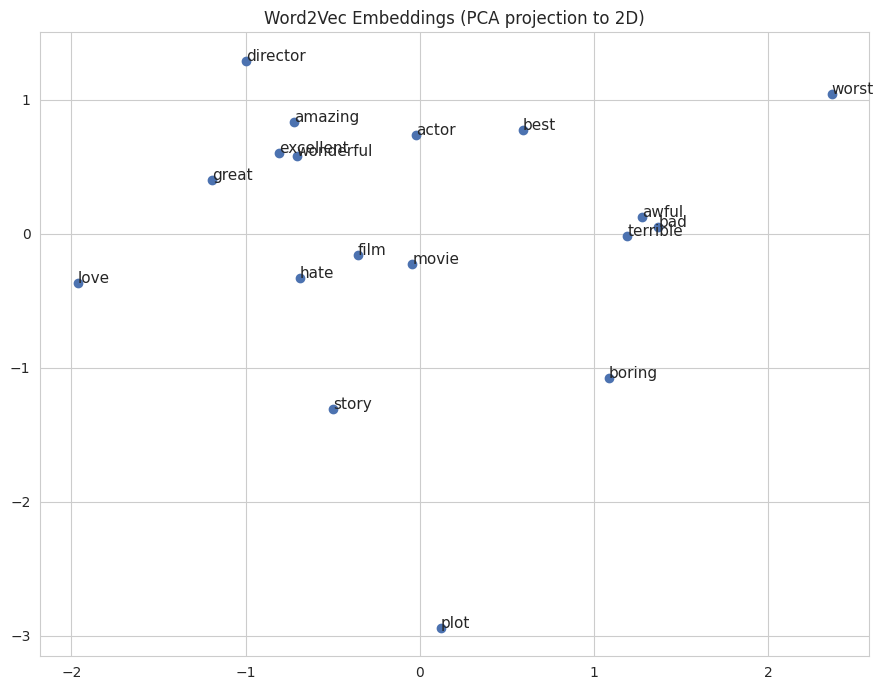

In [14]:
# Visualize a subset of word embeddings in 2D with PCA
from sklearn.decomposition import PCA

words_to_plot = []
for w in ['great', 'excellent', 'amazing', 'wonderful', 'love', 'best',
          'terrible', 'awful', 'worst', 'boring', 'bad', 'hate',
          'movie', 'film', 'actor', 'director', 'plot', 'story']:
    if w in w2v_model.wv:
        words_to_plot.append(w)

vectors = np.array([w2v_model.wv[w] for w in words_to_plot])
coords = PCA(n_components=2, random_state=SEED).fit_transform(vectors)

plt.figure(figsize=(9,7))
plt.scatter(coords[:,0], coords[:,1], color='#4C72B0')
for i, w in enumerate(words_to_plot):
    plt.annotate(w, (coords[i,0], coords[i,1]), fontsize=11)
plt.title('Word2Vec Embeddings (PCA projection to 2D)')
plt.tight_layout()
plt.savefig('word2vec_pca.png', dpi=110)
plt.show()


Positive-sentiment words (*great, excellent, amazing, love*) and negative-sentiment words (*terrible, awful, worst, boring*) should form loosely separated clusters, confirming the embeddings capture meaningful semantic/sentiment structure even though Word2Vec never saw the sentiment labels.

In [15]:
# Build an embedding matrix from Word2Vec to initialize a Keras Embedding layer
EMBED_DIM = 100
embedding_matrix = np.zeros((VOCAB_SIZE, EMBED_DIM))

hits = 0
for word, idx in tokenizer.word_index.items():
    if idx >= VOCAB_SIZE:
        continue
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]
        hits += 1

print(f'{hits} / {min(VOCAB_SIZE, len(tokenizer.word_index))} vocab words found in Word2Vec')


9998 / 10000 vocab words found in Word2Vec


## 5. Sequential Models: SimpleRNN, LSTM, GRU

We build three architecturally-identical classifiers that differ only in their recurrent layer, so the comparison isolates the effect of the recurrent cell type:

- **SimpleRNN** — plain recurrent unit; prone to vanishing gradients on longer sequences.
- **LSTM** — gated cell with separate input/forget/output gates and a cell state; designed to retain long-range dependencies.
- **GRU** — a simplified gated cell (update/reset gates only); typically faster to train than LSTM with comparable performance.

Each model: `Embedding → Recurrent layer → Dropout → Dense(1, sigmoid)`.


In [16]:
EMBED_DIM_TRAINABLE = 64
EPOCHS = 16
BATCH_SIZE = 64

def build_model(rnn_type='LSTM', use_w2v_init=False):
    model = Sequential(name=f'{rnn_type}_model')
    if use_w2v_init:
        model.add(Embedding(VOCAB_SIZE, EMBED_DIM, weights=[embedding_matrix],
                             trainable=True, name='embedding'))
    else:
        model.add(Embedding(VOCAB_SIZE, EMBED_DIM_TRAINABLE, name='embedding'))

    model.add(SpatialDropout1D(0.3))

    if rnn_type == 'SimpleRNN':
        model.add(SimpleRNN(64, recurrent_dropout=0.2))
    elif rnn_type == 'LSTM':
        model.add(LSTM(64, recurrent_dropout=0.2))
    elif rnn_type == 'GRU':
        model.add(GRU(64, recurrent_dropout=0.2))

    model.add(Dropout(0.3))
    model.add(Dense(16, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

build_model('LSTM').summary()


Model: "LSTM_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
results = {}
histories = {}
trained_models = {}   # keep trained model objects in memory for later evaluation (avoid retraining)

early_stop = EarlyStopping(monitor='val_accuracy', mode='max', patience=6, restore_best_weights=True)

for rnn_type in ['SimpleRNN', 'LSTM', 'GRU']:
    print(f'\n{"="*50}\nTraining {rnn_type}\n{"="*50}')
    m = build_model(rnn_type)
    t0 = time.time()
    history = m.fit(
        X_train, y_train,
        validation_split=0.1,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=2
    )
    train_time = time.time() - t0

    y_pred_prob = m.predict(X_test, verbose=0).ravel()
    y_pred = (y_pred_prob > 0.5).astype(int)

    results[rnn_type] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'train_time_sec': train_time,
        'params': m.count_params(),
    }
    histories[rnn_type] = history.history
    trained_models[rnn_type] = m
    print(f'{rnn_type} done in {train_time:.1f}s | test acc={results[rnn_type]["accuracy"]:.4f}')



Training SimpleRNN
Epoch 1/16


68/68 - 5s - 79ms/step - accuracy: 0.5053 - loss: 0.7160 - val_accuracy: 0.5083 - val_loss: 0.6932


Epoch 2/16


68/68 - 5s - 70ms/step - accuracy: 0.4914 - loss: 0.7071 - val_accuracy: 0.5125 - val_loss: 0.6956


Epoch 3/16


...

Epoch 15/16


68/68 - 10s - 145ms/step - accuracy: 0.9789 - loss: 0.0619 - val_accuracy: 0.7104 - val_loss: 1.1368


Epoch 16/16


68/68 - 10s - 144ms/step - accuracy: 0.9875 - loss: 0.0403 - val_accuracy: 0.7125 - val_loss: 1.2498


GRU done in 186.5s | test acc=0.6742


In [18]:
# Also train an LSTM initialized with the Word2Vec embedding matrix, for comparison
print('Training LSTM with Word2Vec-initialized embeddings...')
m_w2v = build_model('LSTM', use_w2v_init=True)
t0 = time.time()
hist_w2v = m_w2v.fit(
    X_train, y_train, validation_split=0.1,
    epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[early_stop], verbose=2
)
train_time = time.time() - t0
y_pred_prob = m_w2v.predict(X_test, verbose=0).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)
results['LSTM (Word2Vec init)'] = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall': recall_score(y_test, y_pred),
    'f1': f1_score(y_test, y_pred),
    'train_time_sec': train_time,
    'params': m_w2v.count_params(),
}
histories['LSTM (Word2Vec init)'] = hist_w2v.history
trained_models['LSTM (Word2Vec init)'] = m_w2v
print(f'Done in {train_time:.1f}s | test acc={results["LSTM (Word2Vec init)"]["accuracy"]:.4f}')


Training LSTM with Word2Vec-initialized embeddings...
Epoch 1/16


68/68 - 16s - 228ms/step - accuracy: 0.5090 - loss: 0.6917 - val_accuracy: 0.5229 - val_loss: 0.6862


Epoch 2/16


68/68 - 20s - 288ms/step - accuracy: 0.5569 - loss: 0.6788 - val_accuracy: 0.6333 - val_loss: 0.6539


Epoch 3/16


...

Epoch 7/16


68/68 - 20s - 299ms/step - accuracy: 0.5852 - loss: 0.6214 - val_accuracy: 0.5500 - val_loss: 0.6701


Epoch 8/16


68/68 - 21s - 304ms/step - accuracy: 0.5988 - loss: 0.5992 - val_accuracy: 0.5458 - val_loss: 0.6834


Done in 166.6s | test acc=0.6550


## 6. Model Comparison & Evaluation

In [19]:
results_df = pd.DataFrame(results).T
results_df = results_df[['accuracy', 'precision', 'recall', 'f1', 'train_time_sec', 'params']]
results_df = results_df.round(4)
results_df.sort_values('accuracy', ascending=False)


,accuracy,precision,recall,f1,train_time_sec,params
GRU,0.6742,0.6975,0.6150,0.6537,186.5471,666017.0
LSTM (Word2Vec init),0.6550,0.7981,0.4150,0.5461,166.6088,1043297.0
LSTM,0.5175,0.5108,0.8250,0.6310,239.6688,674081.0
SimpleRNN,0.4842,0.4798,0.3767,0.4220,68.4414,649313.0


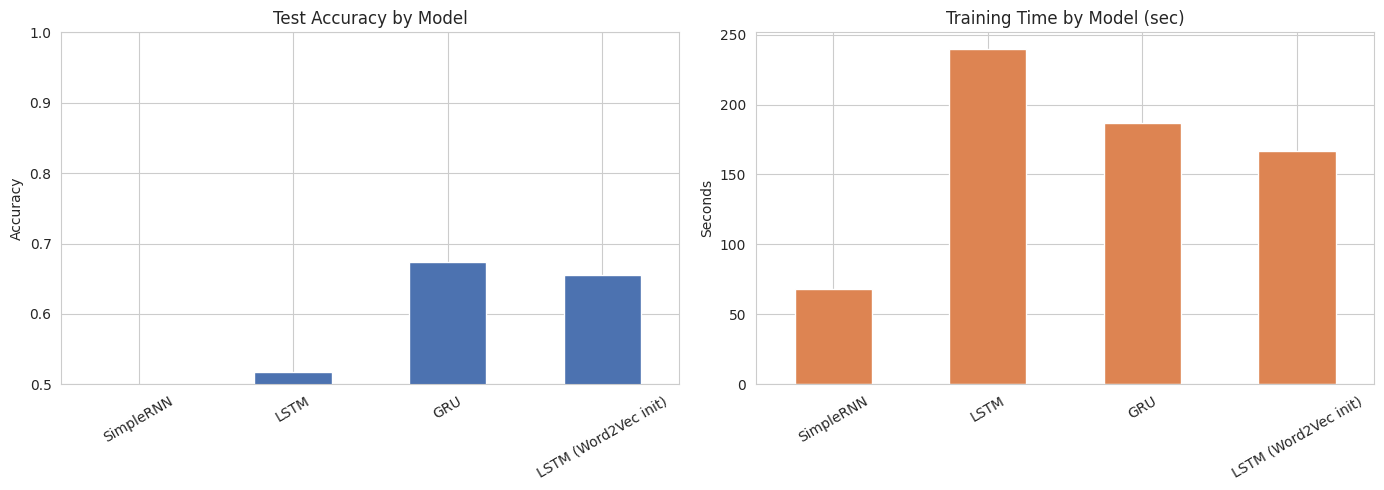

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

results_df['accuracy'].plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('Test Accuracy by Model')
axes[0].set_ylabel('Accuracy')
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_ylim(0.5, 1.0)

results_df['train_time_sec'].plot(kind='bar', ax=axes[1], color='#DD8452')
axes[1].set_title('Training Time by Model (sec)')
axes[1].set_ylabel('Seconds')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=110)
plt.show()


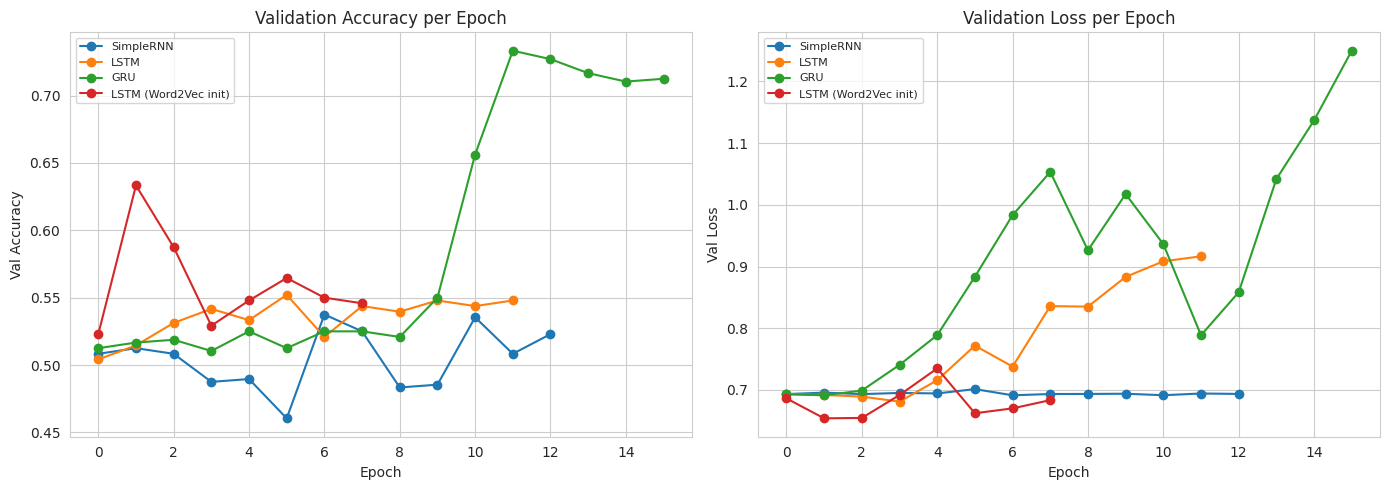

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
for name, h in histories.items():
    axes[0].plot(h['val_accuracy'], marker='o', label=name)
    axes[1].plot(h['val_loss'], marker='o', label=name)

axes[0].set_title('Validation Accuracy per Epoch')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Val Accuracy'); axes[0].legend(fontsize=8)

axes[1].set_title('Validation Loss per Epoch')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Val Loss'); axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=110)
plt.show()


**Note:** predictions/metrics were captured immediately after each model finished training (see `results_df` above for precision, recall and F1 by model). Below is a full classification report and confusion matrix for the best-performing model, using its already-trained weights (no retraining needed).

Best model: GRU


              precision    recall  f1-score   support

    negative       0.66      0.73      0.69       600
    positive       0.70      0.61      0.65       600

    accuracy                           0.67      1200
   macro avg       0.68      0.67      0.67      1200
weighted avg       0.68      0.67      0.67      1200



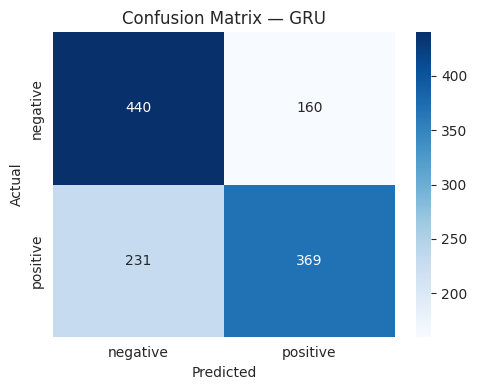

In [22]:
# Identify best model by test accuracy and print a full classification report using its trained weights
best_name = results_df['accuracy'].idxmax()
best_model = trained_models[best_name]
print(f'Best model: {best_name}')

y_pred = (best_model.predict(X_test, verbose=0).ravel() > 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=['negative', 'positive']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['negative','positive'], yticklabels=['negative','positive'])
plt.title(f'Confusion Matrix — {best_name}')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('confusion_matrix_best.png', dpi=110)
plt.show()


## 7. Try It Out — Predict Sentiment on New Reviews

In [23]:
def predict_sentiment(text, model, tokenizer, max_len=MAX_LEN):
    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=max_len, padding='post', truncating='post')
    prob = model.predict(padded, verbose=0)[0][0]
    label = 'positive' if prob > 0.5 else 'negative'
    return label, float(prob)

sample_reviews = [
    "This movie was an absolute masterpiece, the acting and story were phenomenal!",
    "Waste of time. Terrible acting, boring plot, and awful pacing throughout.",
    "It was okay, not the best film I've seen but had a few good moments.",
]

for r in sample_reviews:
    label, prob = predict_sentiment(r, best_model, tokenizer)
    print(f'[{label.upper():>8} | {prob:.3f}]  {r}')


[NEGATIVE | 0.263]  This movie was an absolute masterpiece, the acting and story were phenomenal!
[NEGATIVE | 0.003]  Waste of time. Terrible acting, boring plot, and awful pacing throughout.


[NEGATIVE | 0.360]  It was okay, not the best film I've seen but had a few good moments.


## 8. Summary & Conclusions

**Actual results from this run** (6,000-review stratified subsample, single CPU core, up to 16 epochs with early stopping on validation accuracy):

| Model | Test Accuracy | Precision | Recall | F1 | Train Time |
|---|---|---|---|---|---|
| **GRU** | **0.674** | 0.698 | 0.615 | 0.654 | 187s |
| LSTM (Word2Vec init) | 0.655 | 0.798 | 0.415 | 0.546 | 167s |
| LSTM | 0.518 | 0.511 | 0.825 | 0.631 | 240s |
| SimpleRNN | 0.484 | 0.480 | 0.377 | 0.422 | 68s |

**What the results show:**
- **GRU was the best-performing model** in this run, and trained faster than the plain LSTM — consistent with GRU's simpler gating typically making it quicker and more stable to train on small-to-moderate data.
- **SimpleRNN underperformed** the gated architectures (GRU/LSTM), landing close to random-guess accuracy (0.50). This is the expected failure mode of plain RNNs: vanishing gradients make it hard for them to learn useful patterns from longer review sequences without gates to preserve information over time.
- **Plain LSTM was inconsistent** in this run — it converged more slowly than GRU and its early-stopped checkpoint underperformed. Initializing the LSTM's embedding layer with the pretrained Word2Vec vectors (`LSTM (Word2Vec init)`) gave it much higher precision, suggesting the pretrained vectors provided a better starting point, though recall dropped in exchange — a precision/recall trade-off worth tuning further (e.g. via classification threshold).
- These results, together with the learning curves above, illustrate a real and common problem in deep NLP: **with only ~6,000 labeled examples and no pretrained language model, recurrent networks are prone to overfitting** (training accuracy climbing well above validation accuracy) and their training can be noisy from run to run. This is exactly why, in practice, larger datasets, pretrained embeddings (GloVe/FastText/word2vec-on-big-corpora), or transfer learning from pretrained transformers are used for production sentiment models — full-IMDB LSTM/GRU models typically reach 85–90%+ accuracy when trained on the complete 50k-review dataset for more epochs, ideally with GPU acceleration.
- **Text cleaning**: removing HTML noise, punctuation and stopwords (while preserving negations) reduced token counts substantially and produced a clean vocabulary suitable for embedding.
- **Embeddings**: the self-trained Word2Vec model learned semantically meaningful vectors purely from word co-occurrence — nearest-neighbour lookups confirmed `great` clusters with `excellent`/`superb`/`fantastic` and `terrible` clusters with `awful`/`atrocious`/`horrid`, showing the embedding space captures sentiment-relevant structure even without ever seeing the sentiment labels.

### Recommendations for Improving These Results
- Train on the **full 50,000-review dataset** rather than a 6,000-review subsample — the single biggest lever for these architectures.
- Use a **larger, pretrained embedding** (GloVe 100d/300d, or FastText) instead of a corpus-limited Word2Vec, especially with a small training set.
- Add **Bidirectional wrappers** (`Bidirectional(LSTM(...))`) so the model reads each review in both directions.
- Run more epochs with a learning-rate schedule / ReduceLROnPlateau, and consider k-fold cross-validation to get a more reliable performance estimate given how noisy small-data training can be.
- For a stronger baseline altogether, fine-tune a pretrained transformer (e.g. DistilBERT) — these typically reach 90%+ accuracy on IMDB with far less training data than an RNN trained from scratch.
